# Анализ банковских транзакций и выявление мошеннических операций

Цель исследования — изучить структуру банковских транзакций, выявить закономерности мошеннических операций и определить признаки, которые могут использоваться для совершенствования системы фрод-мониторинга.

## 0. Imports and theme

In [43]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', None)

In [44]:
sns.set_theme(style='ticks')

plt.rcParams.update({
    'figure.dpi': 120,
    'savefig.dpi': 300,
    'font.family': 'DejaVu Sans',
    'font.size': 11,
    'axes.titlesize': 15,
    'axes.titleweight': 'semibold',
    'axes.labelsize': 11,
    'axes.labelweight': 'medium',
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'axes.edgecolor': '#333333',
    'axes.linewidth': 0.8,
    'grid.color': '#E5E5E5',
    'grid.linewidth': 0.7,
    'text.color': '#222222',
    'axes.labelcolor': '#333333',
    'xtick.color': '#333333',
    'ytick.color': '#333333',
})

COLORS = ['#527DAA', '#D96B5F']

## Исследовательский анализ данных (EDA)

### 1.1. Первичный анализ структуры данных, типов, пропусков и дубликатов

In [45]:
df = pd.read_csv('../data/raw/bs140513_032310.csv')

df.head()

,step,customer,age,gender,zipcodeOri,merchant,zipMerchant,category,amount,fraud
0,0,'C1093826151','4','M','28007','M348934600','28007','es_transportation',4.55,0
1,0,'C352968107','2','M','28007','M348934600','28007','es_transportation',39.68,0
2,0,'C2054744914','4','F','28007','M1823072687','28007','es_transportation',26.89,0
3,0,'C1760612790','3','M','28007','M348934600','28007','es_transportation',17.25,0
4,0,'C757503768','5','M','28007','M348934600','28007','es_transportation',35.72,0


In [46]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 594643 entries, 0 to 594642
Data columns (total 10 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   step         594643 non-null  int64  
 1   customer     594643 non-null  str    
 2   age          594643 non-null  str    
 3   gender       594643 non-null  str    
 4   zipcodeOri   594643 non-null  str    
 5   merchant     594643 non-null  str    
 6   zipMerchant  594643 non-null  str    
 7   category     594643 non-null  str    
 8   amount       594643 non-null  float64
 9   fraud        594643 non-null  int64  
dtypes: float64(1), int64(2), str(7)
memory usage: 45.4 MB


In [47]:
df.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
step,594643.0,NaN,NaN,NaN,94.986827,51.053632,0.0,52.0,97.0,139.0,179.0
customer,594643,4112,'C1978250683',265,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,594643,8,'2',187310,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,594643,4,'F',324565,NaN,NaN,NaN,NaN,NaN,NaN,NaN
zipcodeOri,594643,1,'28007',594643,NaN,NaN,NaN,NaN,NaN,NaN,NaN
merchant,594643,50,'M1823072687',299693,NaN,NaN,NaN,NaN,NaN,NaN,NaN
zipMerchant,594643,1,'28007',594643,NaN,NaN,NaN,NaN,NaN,NaN,NaN
category,594643,15,'es_transportation',505119,NaN,NaN,NaN,NaN,NaN,NaN,NaN
amount,594643.0,NaN,NaN,NaN,37.890135,111.402831,0.0,13.74,26.9,42.54,8329.96
fraud,594643.0,NaN,NaN,NaN,0.012108,0.109369,0.0,0.0,0.0,0.0,1.0


In [48]:
print('Количество пропусков:')
display(df.isna().sum())

print(f'Полных дубликатов: {df.duplicated().sum()}')

Количество пропусков:


step           0
customer       0
age            0
gender         0
zipcodeOri     0
merchant       0
zipMerchant    0
category       0
amount         0
fraud          0
dtype: int64

Полных дубликатов: 0


In [49]:
categorical_columns = df.select_dtypes(include='str').columns

for col in categorical_columns:
    print(f'\n{col}: {df[col].nunique()} уникальных значений')
    print(df[col].value_counts().head(10))


customer: 4112 уникальных значений
customer
'C1978250683'    265
'C1275518867'    252
'C806399525'     237
'C515668508'     205
'C1338396147'    195
'C1896850232'    192
'C1350963410'    191
'C980876590'     189
'C582688427'     188
'C1090528803'    188
Name: count, dtype: int64

age: 8 уникальных значений
age
'2'    187310
'3'    147131
'4'    109025
'5'     62642
'1'     58131
'6'     26774
'0'      2452
'U'      1178
Name: count, dtype: int64

gender: 4 уникальных значений
gender
'F'    324565
'M'    268385
'E'      1178
'U'       515
Name: count, dtype: int64

zipcodeOri: 1 уникальных значений
zipcodeOri
'28007'    594643
Name: count, dtype: int64

merchant: 50 уникальных значений
merchant
'M1823072687'    299693
'M348934600'     205426
'M85975013'       26254
'M1053599405'      6821
'M151143676'       6373
'M855959430'       6098
'M1946091778'      5343
'M1913465890'      3988
'M209847108'       3814
'M480139044'       3508
Name: count, dtype: int64

zipMerchant: 1 уникальных зна

In [50]:
print('Возрастные категории:')
print(sorted(df['age'].unique()))

print('\nРаспределение по полу:')
print(df['gender'].value_counts())

print(f"Количество временных шагов: {df['step'].nunique()}")
print(f"Минимальный шаг: {df['step'].min()}")
print(f"Максимальный шаг: {df['step'].max()}")

constant_columns = [
    col for col in df.columns
    if df[col].nunique() == 1
]

print('Признаки с одним уникальным значением:', constant_columns)

Возрастные категории:
["'0'", "'1'", "'2'", "'3'", "'4'", "'5'", "'6'", "'U'"]

Распределение по полу:
gender
'F'    324565
'M'    268385
'E'      1178
'U'       515
Name: count, dtype: int64
Количество временных шагов: 180
Минимальный шаг: 0
Максимальный шаг: 179
Признаки с одним уникальным значением: ['zipcodeOri', 'zipMerchant']


### Выводы по первичному анализу

На этом этапе удалось разобраться с общей структурой датасета и особенностями признаков.

- В данных представлено 4 112 клиентов. Количество операций у них заметно различается: некоторые клиенты встречаются в датасете гораздо чаще остальных. Это пригодится при дальнейшем анализе поведения отдельных клиентов.
- Признак `age` содержит не точный возраст, а несколько категорий (`0`–`6` и `U`). Поэтому рассматривать его как обычный числовой признак пока не стоит.
- В `gender` преобладают категории `F` и `M`, но также встречаются редкие значения `E` и `U`. Пока оставим их — возможно, при анализе мошеннических операций они окажутся интересными.
- `step` содержит 180 временных шагов. Этого достаточно, чтобы посмотреть на динамику транзакций, но информации о конкретных часах и днях недели в датасете нет.
- `zipcodeOri` и `zipMerchant` содержат одинаковые значения во всех строках. Для дальнейшего анализа они бесполезны, поэтому их можно будет исключить.

В целом данные достаточно чистые: пропусков и полных дубликатов нет. При этом уже видны некоторые особенности, которые важно учитывать при анализе. Например, идентификаторы клиентов пригодятся для изучения последовательностей операций, а категориальные признаки потребуют отдельного внимания.

Дальше посмотрим на целевую переменную `fraud`: насколько часто встречаются мошеннические операции и чем они отличаются от обычных транзакций.

### 1.2. Анализ целевой переменной и дисбаланса классов.

Перед тем как переходить к поиску закономерностей, посмотрим на распределение целевой переменной `fraud`. Будем обращать внимание не только на количество мошеннических операций, но и на то, насколько сильно они отличаются по сумме от обычных транзакций.

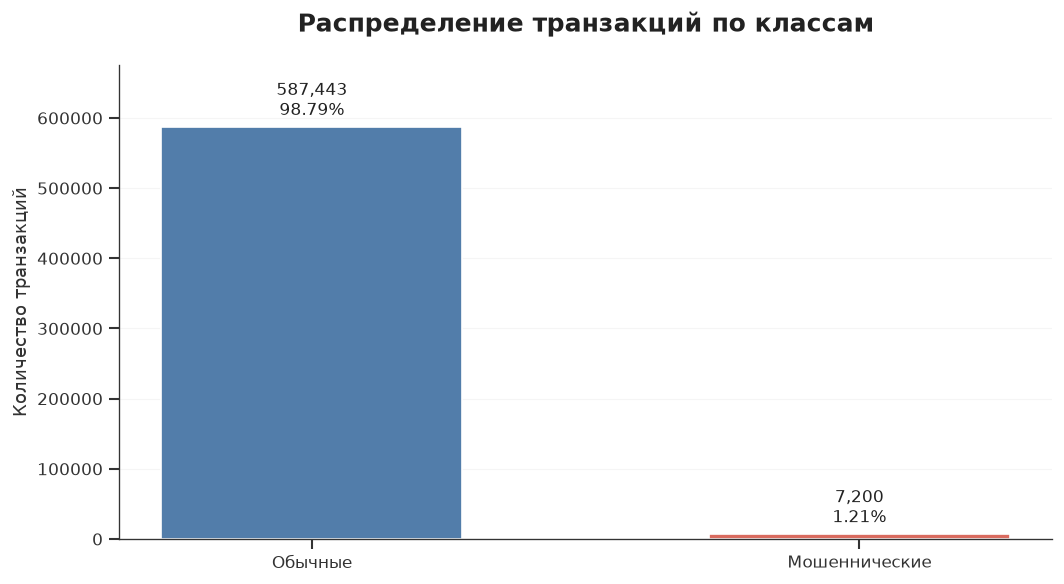

In [51]:
fraud_counts = df['fraud'].value_counts().sort_index()
fraud_percent = df['fraud'].value_counts(normalize=True).sort_index() * 100

fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(
    ['Обычные', 'Мошеннические'],
    fraud_counts.values,
    color=COLORS,
    width=0.55
)

for bar, count, percent in zip(bars, fraud_counts.values, fraud_percent.values):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + fraud_counts.max() * 0.015,
        f'{count:,.0f}\n{percent:.2f}%',
        ha='center',
        va='bottom',
        fontsize=10
    )

ax.set_title('Распределение транзакций по классам', pad=20)
ax.set_ylabel('Количество транзакций')
ax.set_ylim(0, fraud_counts.max() * 1.15)
ax.spines[['top', 'right']].set_visible(False)
ax.grid(axis='y', alpha=0.35)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

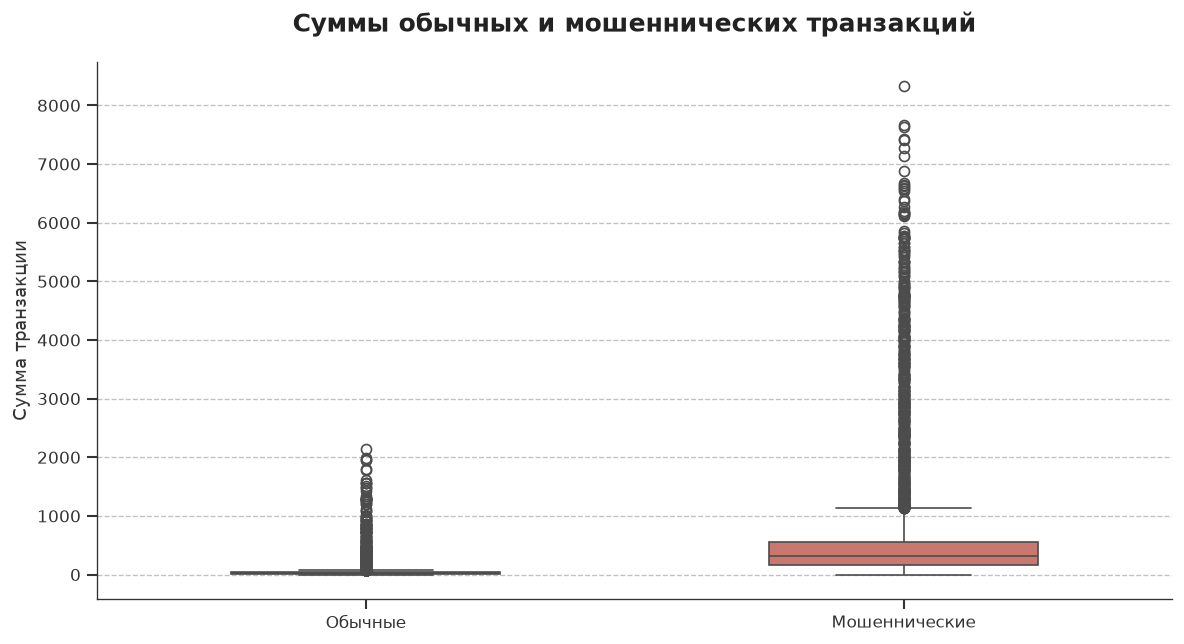

In [52]:
fig, ax = plt.subplots(figsize=(10, 5.5))

sns.boxplot(
    data=df,
    x='fraud',
    y='amount',
    hue='fraud',
    palette=COLORS,
    width=0.5,
    showfliers=True,
    legend=False,
    ax=ax
)

ax.set_title('Суммы обычных и мошеннических транзакций', pad=18)
ax.set_xlabel('')
ax.set_ylabel('Сумма транзакции')
ax.set_xticks([0, 1], ['Обычные', 'Мошеннические'])

ax.set_axisbelow(True)
ax.grid(False)
ax.yaxis.set_major_locator(plt.MaxNLocator(10))
ax.yaxis.grid(True, color='#A0A0A0', linestyle='--', linewidth=0.8, alpha=0.65)

ax.spines[['top', 'right']].set_visible(False)

plt.tight_layout()
plt.show()

На исходном графике из-за больших значений и выбросов основная часть распределения оказалась сильно сжатой. Чтобы лучше рассмотреть различия между операциями, применим логарифмическое преобразование.

Используем `log1p`: оно вычисляет натуральный логарифм от `1 + amount` и позволяет корректно обработать нулевые суммы, которые тоже присутствуют в данных.

In [53]:
df['log_amount'] = np.log1p(df['amount'])

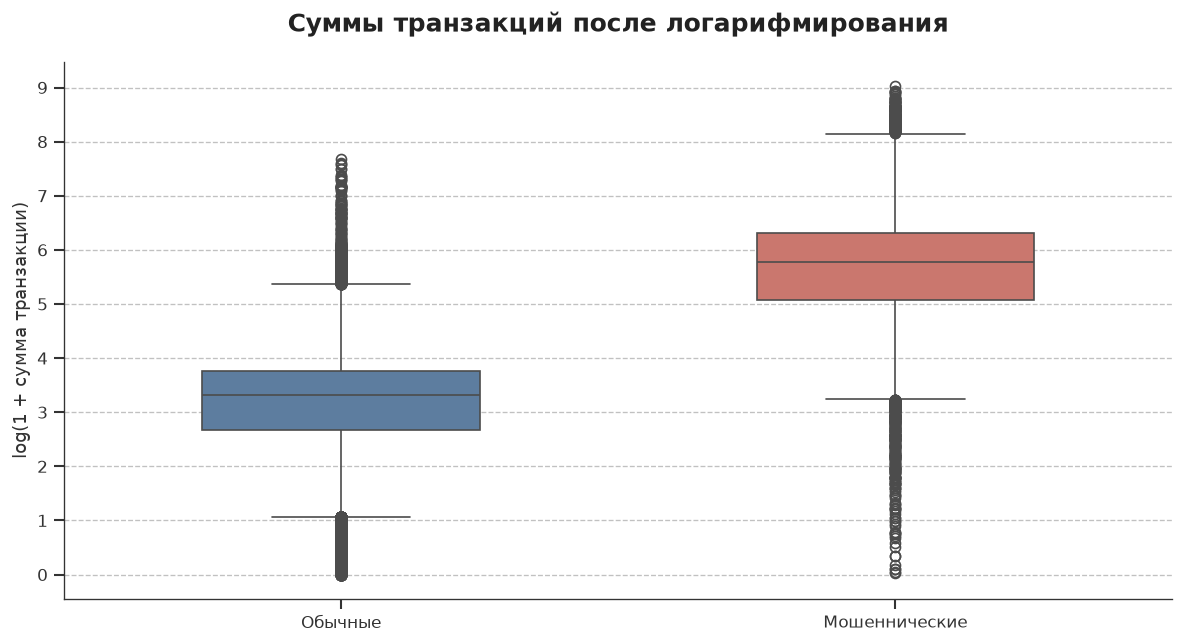

In [54]:
df['log_amount'] = np.log1p(df['amount'])

fig, ax = plt.subplots(figsize=(10, 5.5))

sns.boxplot(
    data=df,
    x='fraud',
    y='log_amount',
    hue='fraud',
    palette=COLORS,
    width=0.5,
    showfliers=True,
    legend=False,
    ax=ax
)

ax.set_title('Суммы транзакций после логарифмирования', pad=18)
ax.set_xlabel('')
ax.set_ylabel('log(1 + сумма транзакции)')
ax.set_xticks([0, 1], ['Обычные', 'Мошеннические'])

ax.set_axisbelow(True)
ax.grid(False)
ax.yaxis.set_major_locator(plt.MaxNLocator(10))
ax.yaxis.grid(True, color='#A0A0A0', linestyle='--', linewidth=0.8, alpha=0.65)

ax.spines[['top', 'right']].set_visible(False)

plt.tight_layout()
plt.show()

### Сравнение статистик по классам

Чтобы дополнить визуальный анализ, рассчитаем основные статистики отдельно для обычных и мошеннических транзакций.

Посмотрим на среднюю и медианную суммы, стандартное отклонение, минимальные и максимальные значения, а также квартили. Это поможет точнее оценить различия между двумя группами и понять, насколько на распределение влияют крупные операции.

In [55]:
amount_stats = df.groupby('fraud')['amount'].agg(
    ['count', 'mean', 'median', 'std', 'min', 'max']
)

amount_stats['q25'] = df.groupby('fraud')['amount'].quantile(0.25)
amount_stats['q75'] = df.groupby('fraud')['amount'].quantile(0.75)

amount_stats.index = ['Обычные', 'Мошеннические']

amount_stats.round(2)

,count,mean,median,std,min,max,q25,q75
Обычные,587443,31.85,26.61,31.47,0.00,2144.86,13.59,41.90
Мошеннические,7200,530.93,319.18,835.59,0.03,8329.96,159.98,548.98


И отдельно сравним суммы после логарифмирования

In [56]:
log_stats = df.groupby('fraud')['log_amount'].agg(
    ['mean', 'median', 'std', 'min', 'max']
)

log_stats.index = ['Обычные', 'Мошеннические']

log_stats.round(2)

,mean,median,std,min,max
Обычные,3.15,3.32,0.91,0.00,7.67
Мошеннические,5.64,5.77,1.19,0.03,9.03


### Выводы по анализу сумм транзакций

Между обычными и мошенническими операциями заметна существенная разница:

- Средняя сумма мошеннической транзакции — 530.93 против 31.85 у обычной.
- Медиана тоже сильно отличается: 319.18 против 26.61. Значит, дело не только в нескольких крупных выбросах.
- У мошеннических операций гораздо сильнее разброс сумм.
- После логарифмирования различия между классами сохраняются, но распределение становится удобнее для визуального анализа.

Получается, что сумма транзакции может быть полезным признаком при выявлении мошенничества. При этом использовать только порог по сумме было бы неправильно: мошеннические операции могут быть разными по размеру, а крупная покупка сама по себе ещё не означает мошенничество.

Отдельно стоит учитывать сильный дисбаланс классов: мошеннических операций значительно меньше, чем обычных. Поэтому в дальнейшем важно оценивать не только количество найденных подозрительных операций, но и долю действительно мошеннических среди них.

### 1.3. Анализ мошенничества по категориям операций

Теперь посмотрим, как мошеннические операции распределяются между категориями транзакций.

Здесь важно не ограничиваться простым подсчётом мошеннических операций: в популярных категориях их может быть больше просто потому, что там совершается больше покупок. Поэтому дополнительно рассчитаем долю мошенничества внутри каждой категории.

#### Количество операций и доля мошенничества

In [57]:
category_stats = df.groupby('category').agg(
    transactions=('fraud', 'count'),
    fraud_count=('fraud', 'sum'),
    fraud_rate=('fraud', 'mean')
)

category_stats['fraud_rate'] *= 100
category_stats = category_stats.sort_values('fraud_rate', ascending=False)

category_stats.round(2)

,transactions,fraud_count,fraud_rate
category,,,
'es_leisure',499,474,94.99
'es_travel',728,578,79.40
'es_sportsandtoys',4002,1982,49.53
'es_hotelservices',1744,548,31.42
'es_otherservices',912,228,25.00
'es_home',1986,302,15.21
'es_health',16133,1696,10.51
'es_tech',2370,158,6.67
'es_wellnessandbeauty',15086,718,4.76


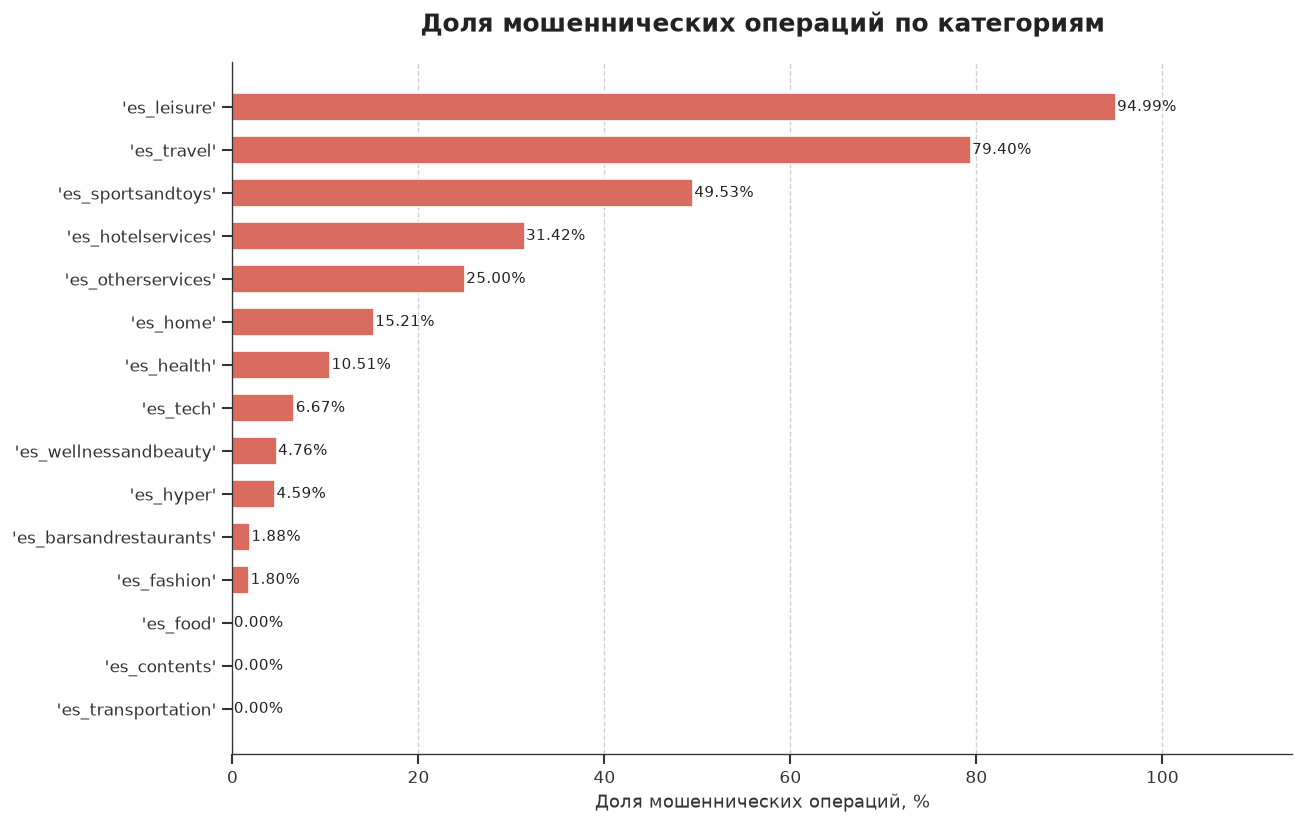

In [58]:
plot_data = category_stats.sort_values('fraud_rate')

fig, ax = plt.subplots(figsize=(11, 7))

bars = ax.barh(
    plot_data.index,
    plot_data['fraud_rate'],
    color='#D96B5F',
    height=0.65
)

for bar in bars:
    ax.text(
        bar.get_width() + 0.15,
        bar.get_y() + bar.get_height() / 2,
        f'{bar.get_width():.2f}%',
        va='center',
        fontsize=9
    )

ax.set_title('Доля мошеннических операций по категориям', pad=18)
ax.set_xlabel('Доля мошеннических операций, %')
ax.set_ylabel('')
ax.set_xlim(0, plot_data['fraud_rate'].max() * 1.2)

ax.set_axisbelow(True)
ax.grid(False)
ax.xaxis.grid(True, color='#A0A0A0', linestyle='--', linewidth=0.8, alpha=0.5)
ax.spines[['top', 'right']].set_visible(False)

plt.tight_layout()
plt.show()

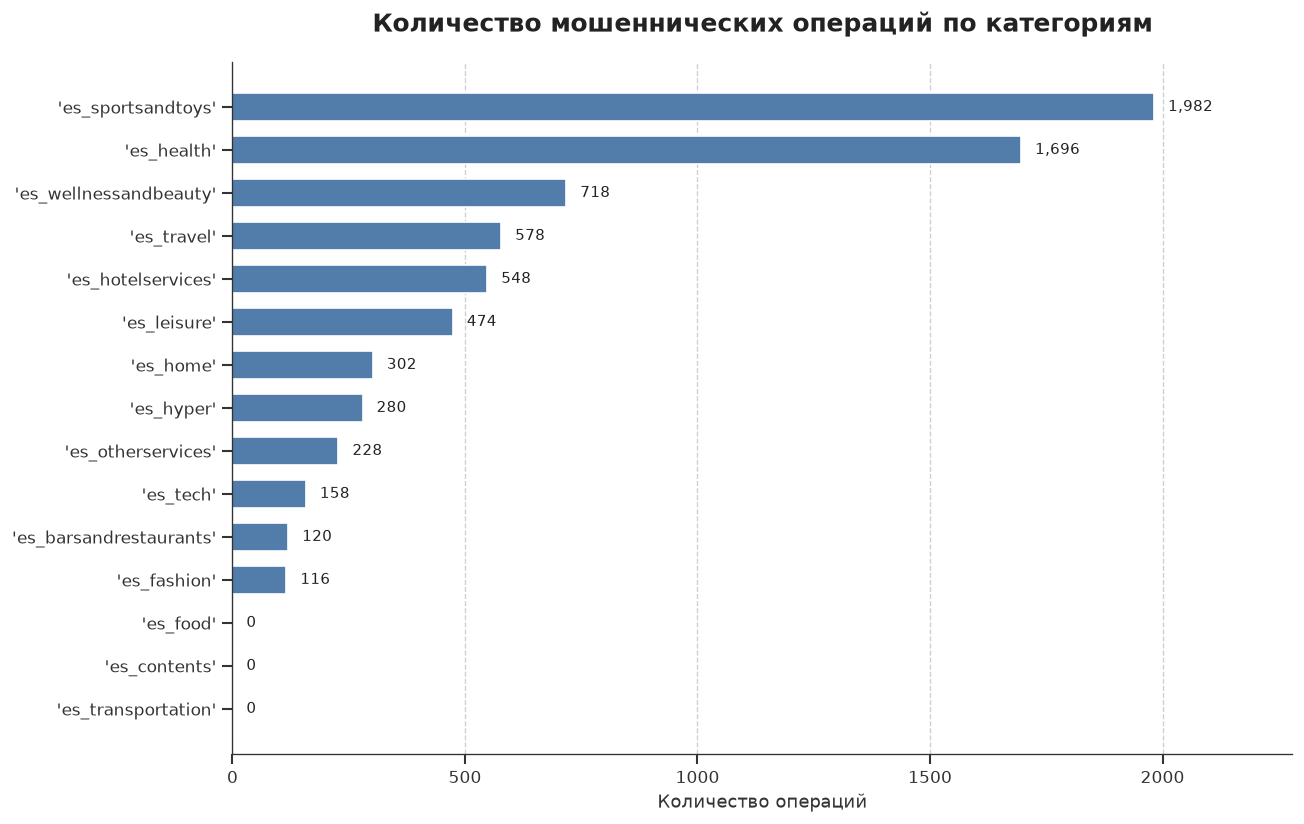

In [59]:
plot_data = category_stats.sort_values('fraud_count')

fig, ax = plt.subplots(figsize=(11, 7))

bars = ax.barh(
    plot_data.index,
    plot_data['fraud_count'],
    color='#527DAA',
    height=0.65
)

for bar in bars:
    ax.text(
        bar.get_width() + 30,
        bar.get_y() + bar.get_height() / 2,
        f'{bar.get_width():,.0f}',
        va='center',
        fontsize=9
    )

ax.set_title('Количество мошеннических операций по категориям', pad=18)
ax.set_xlabel('Количество операций')
ax.set_ylabel('')
ax.set_xlim(0, plot_data['fraud_count'].max() * 1.15)

ax.set_axisbelow(True)
ax.grid(False)
ax.xaxis.grid(True, color='#A0A0A0', linestyle='--', linewidth=0.8, alpha=0.5)
ax.spines[['top', 'right']].set_visible(False)

plt.tight_layout()
plt.show()

### Выводы по категориям операций

Распределение мошенничества по категориям оказалось довольно неравномерным:

- Самая высокая доля мошенничества наблюдается в `es_leisure` — почти 95%, а также в `es_travel` — около 79%.
- В `es_sportsandtoys` мошенническими оказались почти половина операций (49.53%). При этом здесь уже достаточно большая выборка — 4 002 транзакции.
- В `es_health` доля мошенничества составляет 10.51%, но из-за большого количества операций категория даёт наибольшее число мошеннических случаев среди категорий с более умеренным уровнем риска — 1 696.
- В категориях `es_food`, `es_contents` и `es_transportation` мошеннических операций в выборке не обнаружено. Но отсутствие мошенничества в категории не гарантирует, что она безопасна.

Таким образом, категория операции может быть одним из сильных признаков при оценке риска. Особенно выделяются leisure, travel и sportsandtoys. При этом важно учитывать не только процент мошенничества, но и размер выборки: по категориям с небольшим количеством операций выводы могут быть менее устойчивыми.

### 1.4. Анализ клиентской активности.

До этого мы рассматривали транзакции в целом, теперь посмотрим на них с точки зрения отдельных клиентов.

Посчитаем количество операций и долю мошеннических транзакций для каждого клиента. Это поможет найти клиентов с необычно высокой долей мошенничества и понять, насколько часто такие операции повторяются.

In [60]:
customer_stats = df.groupby('customer').agg(
    transactions=('fraud', 'count'),
    fraud_count=('fraud', 'sum'),
    fraud_rate=('fraud', 'mean'),
    avg_amount=('amount', 'mean')
)

customer_stats['fraud_rate'] *= 100

Чтобы не делать выводы по клиентам, у которых всего 1–2 транзакции, ограничим выборку теми, у кого не менее 10 операций

In [61]:
active_customers = customer_stats[customer_stats['transactions'] >= 10]

active_customers.sort_values('fraud_rate', ascending=False).head(15).round(2)

,transactions,fraud_count,fraud_rate,avg_amount
customer,,,,
'C910454738',92,87,94.57,410.82
'C2004941826',126,119,94.44,513.90
'C381007057',100,89,89.00,513.89
'C1572610482',101,89,88.12,581.06
'C617723960',46,40,86.96,517.91
'C2113737065',91,79,86.81,432.32
'C2060410910',13,11,84.62,561.95
'C483912131',98,80,81.63,514.93
'C1817318774',112,87,77.68,411.61


In [62]:
active_customers.shape

(4087, 4)

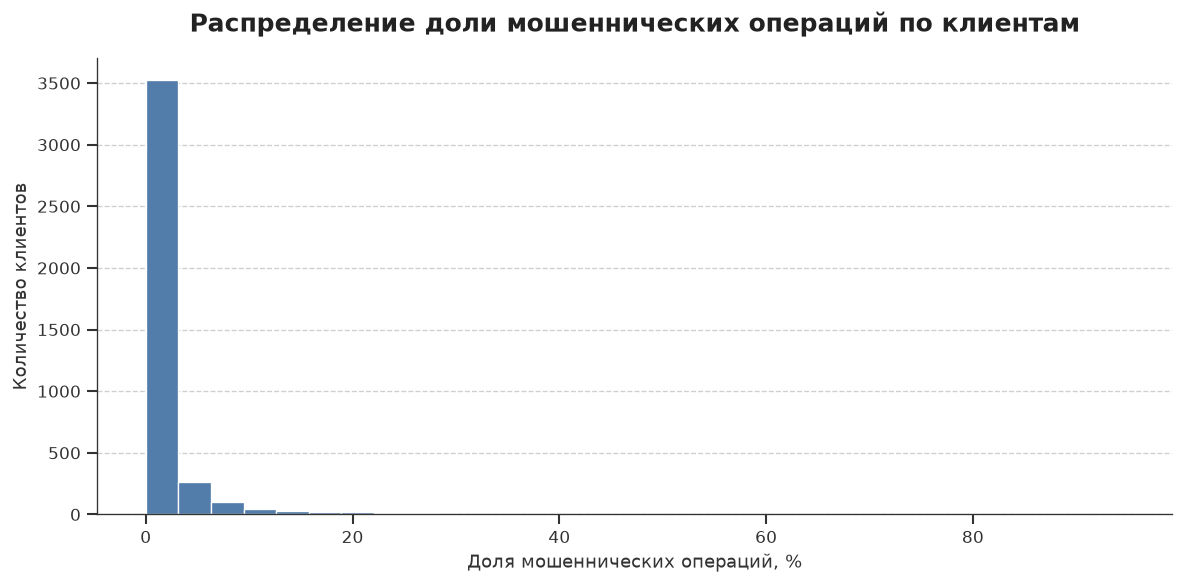

In [63]:
fig, ax = plt.subplots(figsize=(10, 5))

ax.hist(
    active_customers['fraud_rate'],
    bins=30,
    color='#527DAA',
    edgecolor='white',
    linewidth=0.8
)

ax.set_title('Распределение доли мошеннических операций по клиентам', pad=16)
ax.set_xlabel('Доля мошеннических операций, %')
ax.set_ylabel('Количество клиентов')

ax.set_axisbelow(True)
ax.yaxis.grid(True, color='#A0A0A0', linestyle='--', linewidth=0.8, alpha=0.5)
ax.spines[['top', 'right']].set_visible(False)

plt.tight_layout()
plt.show()

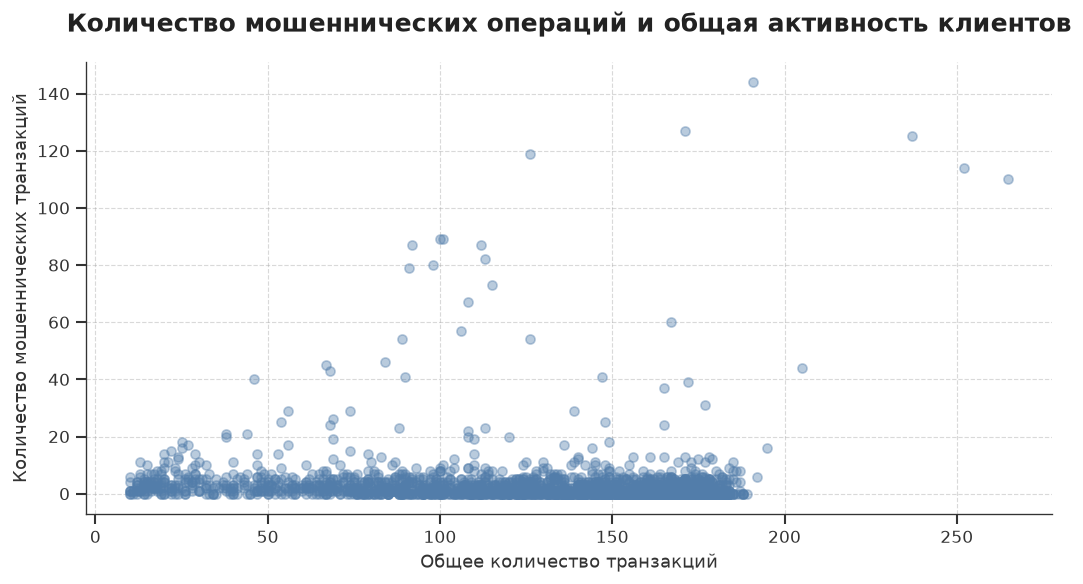

In [64]:
fig, ax = plt.subplots(figsize=(9, 5))

ax.scatter(
    active_customers['transactions'],
    active_customers['fraud_count'],
    alpha=0.4,
    color='#527DAA',
    s=30
)

ax.set_title('Количество мошеннических операций и общая активность клиентов', pad=18)
ax.set_xlabel('Общее количество транзакций')
ax.set_ylabel('Количество мошеннических транзакций')

ax.set_axisbelow(True)
ax.xaxis.grid(True, color='#A0A0A0', linestyle='--', linewidth=0.7, alpha=0.4)
ax.yaxis.grid(True, color='#A0A0A0', linestyle='--', linewidth=0.7, alpha=0.4)
ax.spines[['top', 'right']].set_visible(False)

plt.tight_layout()
plt.show()

### Выводы по анализу клиентов

При анализе клиентской активности обнаружились следующие особенности:

- Есть клиенты с очень высокой долей мошеннических операций — у некоторых она превышает 90%. При этом даже после ограничения выборки клиентами с 10 и более транзакциями такие значения сохраняются.
- На гистограмме видно, что у большинства клиентов доля мошеннических операций близка к нулю. При этом есть небольшая группа клиентов с очень высокой долей — распределение имеет выраженную асимметрию и длинный правый хвост.
- На диаграмме рассеяния основная масса клиентов сосредоточена в области до 200 транзакций и 10 мошеннических операций. Отдельные клиенты заметно выделяются по активности и количеству мошеннических операций.

Таким образом, анализ поведения клиентов может помочь находить группы с нетипичной активностью. При этом большое количество мошеннических операций само по себе ещё не говорит о высокой склонности клиента к мошенничеству — важно учитывать и общее количество его транзакций.

### 1.5. Динамика мошеннических операций во времени (step).

Выясним насколько равномерно мошенничество встречается в течение всего периода и есть ли отдельные периоды с повышенной активностью.

В датасете `step` — условный временной индекс, поэтому анализировать будем общую динамику, не привязываясь к конкретным часам или дням недели.

In [65]:
step_stats = df.groupby('step').agg(
    transactions=('fraud', 'count'),
    fraud_count=('fraud', 'sum'),
    fraud_rate=('fraud', 'mean')
)

step_stats['fraud_rate'] *= 100
step_stats.head()

,transactions,fraud_count,fraud_rate
step,,,
0,2430,40,1.646091
1,2424,40,1.650165
2,2462,40,1.624695
3,2499,40,1.600640
4,2532,40,1.579779


In [66]:
step_stats['fraud_count'].value_counts()

fraud_count
40    180
Name: count, dtype: int64

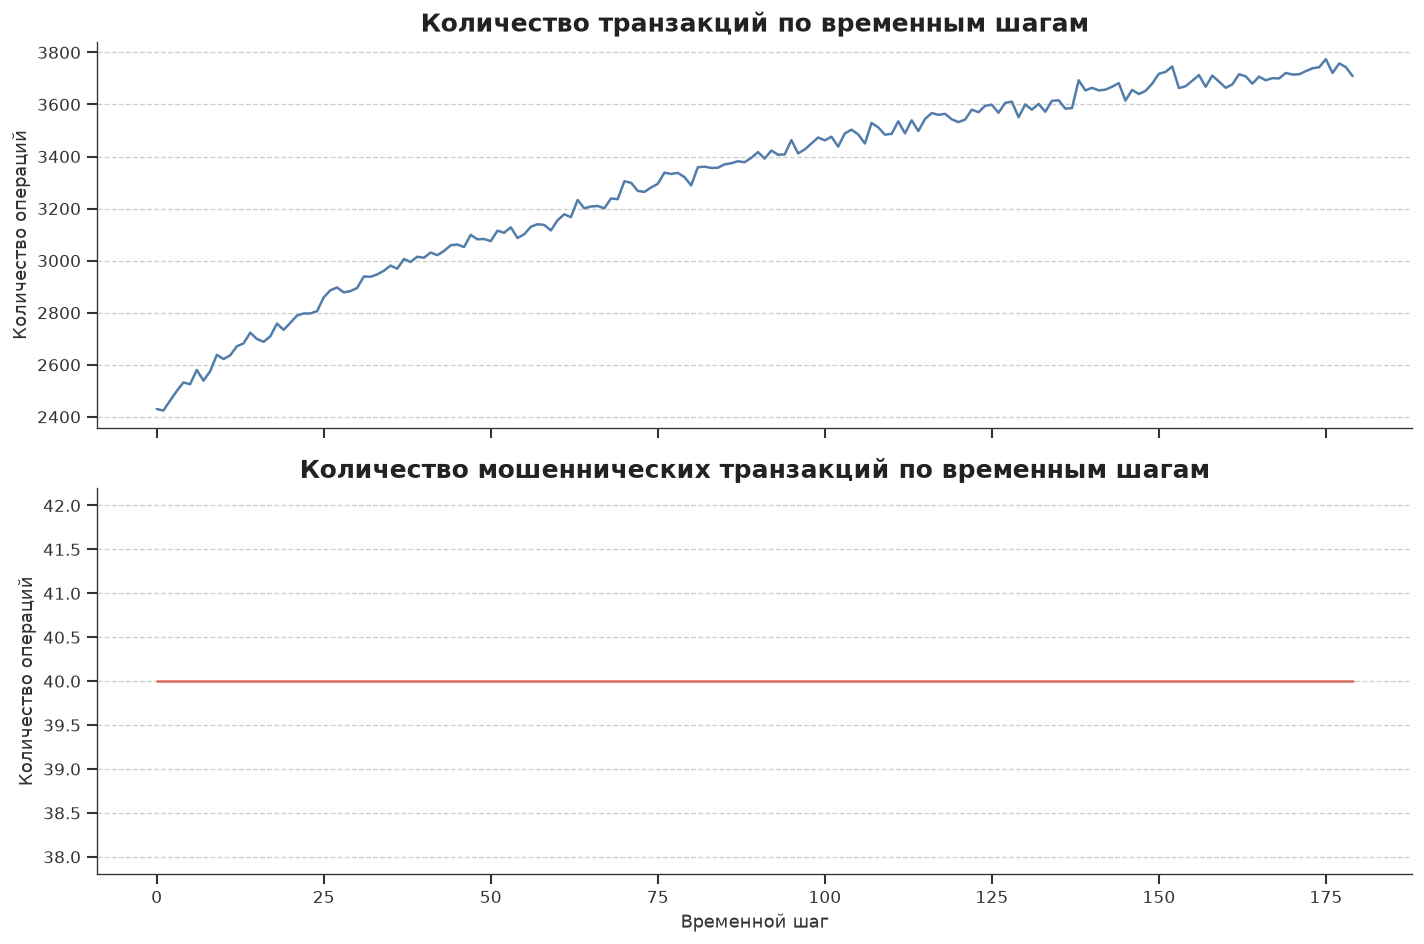

In [67]:
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

axes[0].plot(step_stats.index, step_stats['transactions'], color=COLORS[0])
axes[0].set_title('Количество транзакций по временным шагам')
axes[0].set_ylabel('Количество операций')

axes[1].plot(step_stats.index, step_stats['fraud_count'], color=COLORS[1])
axes[1].set_title('Количество мошеннических транзакций по временным шагам')
axes[1].set_xlabel('Временной шаг')
axes[1].set_ylabel('Количество операций')

for ax in axes:
    ax.set_axisbelow(True)
    ax.yaxis.grid(True, color='#A0A0A0', linestyle='--', linewidth=0.8, alpha=0.5)
    ax.spines[['top', 'right']].set_visible(False)

plt.tight_layout()
plt.show()

### Выводы по динамике мошенничества

Обнаружилась необычная особенность датасета: на каждом из 180 временных шагов присутствует ровно 40 мошеннических транзакций. Это может быть связано с особенностями генерации синтетических данных.

Для нашего анализа это означает, что:
- По количеству мошеннических операций невозможно выделить периоды с повышенной активностью мошенников.
- Изменение `fraud_rate` обусловлено изменением общего количества транзакций, а не количества мошеннических операций.
- Временная динамика в этом датасете имеет ограниченную практическую ценность для выявления мошенничества.

Поэтому не будем рассматривать `step` как самостоятельный индикатор мошеннической активности.

### 1.6. Анализ торговых точек (merchant).

Нас интересует, одинаково ли распределяются мошеннические операции между продавцами или отдельные торговые точки заметно выделяются по доле мошенничества.

Для этого рассчитаем количество транзакций, количество мошеннических операций и долю мошенничества для каждого продавца. Также учтём объём операций, поскольку высокая доля мошенничества при небольшом количестве транзакций может быть случайной особенностью выборки.

In [68]:
merchant_stats = df.groupby('merchant').agg(
    transactions=('fraud', 'count'),
    fraud_count=('fraud', 'sum'),
    fraud_rate=('fraud', 'mean')
)

merchant_stats['fraud_rate'] *= 100
merchant_stats = merchant_stats.sort_values('fraud_rate', ascending=False)

merchant_stats.round(2)

,transactions,fraud_count,fraud_rate
merchant,,,
'M1294758098',191,184,96.34
'M3697346',308,290,94.16
'M1873032707',250,216,86.40
'M732195782',608,518,85.20
'M980657600',1769,1472,83.21
'M1353266412',78,64,82.05
'M857378720',122,92,75.41
'M2080407379',48,36,75.00
'M2011752106',244,166,68.03


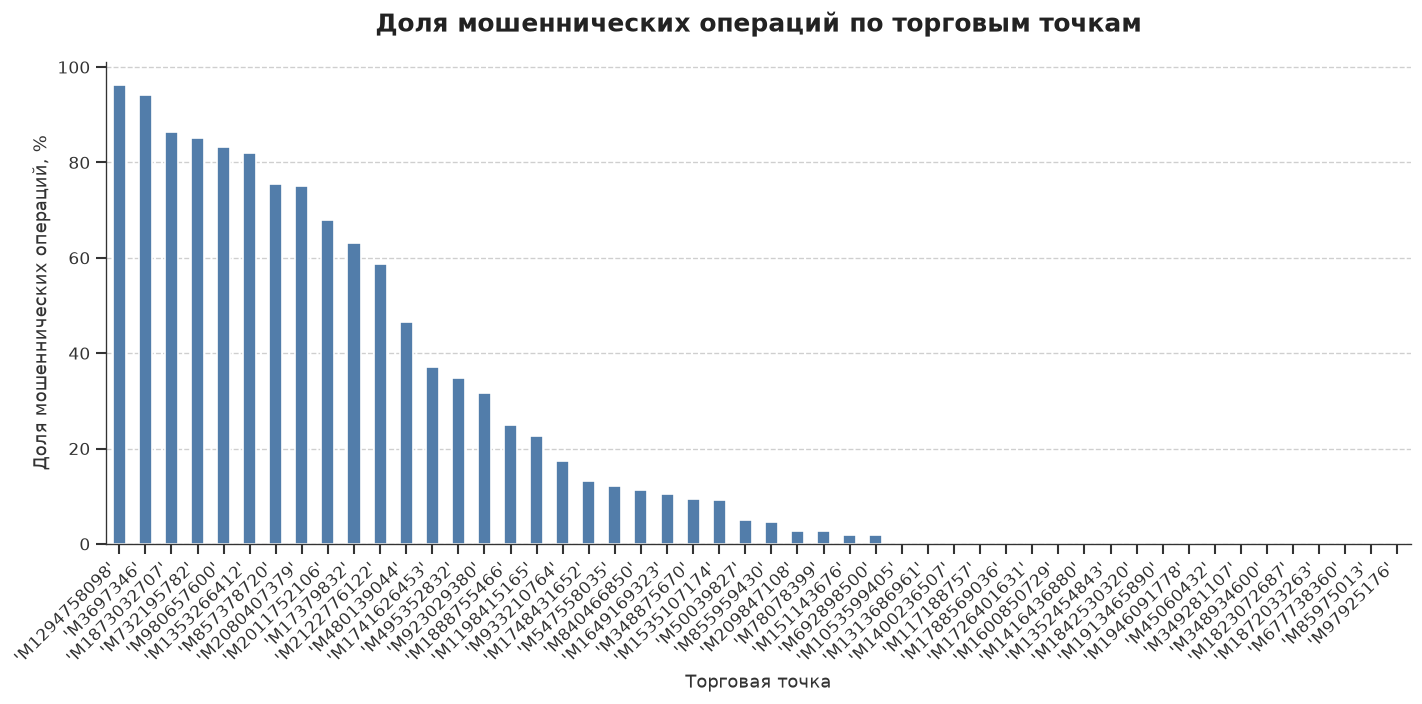

In [69]:
fig, ax = plt.subplots(figsize=(12, 6))

merchant_stats['fraud_rate'].plot(
    kind='bar',
    ax=ax,
    color=COLORS[0],
    edgecolor='white'
)

ax.set_title('Доля мошеннических операций по торговым точкам', pad=18)
ax.set_xlabel('Торговая точка')
ax.set_ylabel('Доля мошеннических операций, %')
ax.set_axisbelow(True)
ax.yaxis.grid(True, color='#A0A0A0', linestyle='--', linewidth=0.8, alpha=0.5)
ax.spines[['top', 'right']].set_visible(False)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

#### Выводы по анализу торговых точек

Мошеннические операции распределены между торговыми точками неравномерно: у отдельных продавцов их доля превышает 80–90%, у других мошенничество не встречается вовсе.

Высокая доля наблюдается и у продавцов с большим количеством транзакций, поэтому `merchant` может быть полезным признаком при оценке риска операции.

При этом важно учитывать объём выборки: высокая доля мошенничества сама по себе не доказывает, что конкретная транзакция мошенническая.

В дальнейшем эти закономерности можно использовать для разработки антифрод-правил и расчёта риск-оценки операций.

### 1.7. Анализ мошенничества по демографическим признакам

In [70]:
age_stats = df.groupby('age').agg(
    transactions=('fraud', 'count'),
    fraud_count=('fraud', 'sum'),
    fraud_rate=('fraud', 'mean')
)

age_stats['fraud_rate'] *= 100
age_stats.sort_values('fraud_rate', ascending=False).round(2)

,transactions,fraud_count,fraud_rate
age,,,
'0',2452,48,1.96
'4',109025,1410,1.29
'2',187310,2344,1.25
'3',147131,1755,1.19
'1',58131,689,1.19
'5',62642,686,1.10
'6',26774,261,0.97
'U',1178,7,0.59


In [71]:
gender_stats = df.groupby('gender').agg(
    transactions=('fraud', 'count'),
    fraud_count=('fraud', 'sum'),
    fraud_rate=('fraud', 'mean')
)

gender_stats['fraud_rate'] *= 100
gender_stats.sort_values('fraud_rate', ascending=False).round(2)

,transactions,fraud_count,fraud_rate
gender,,,
'F',324565,4758,1.47
'M',268385,2435,0.91
'E',1178,7,0.59
'U',515,0,0.00


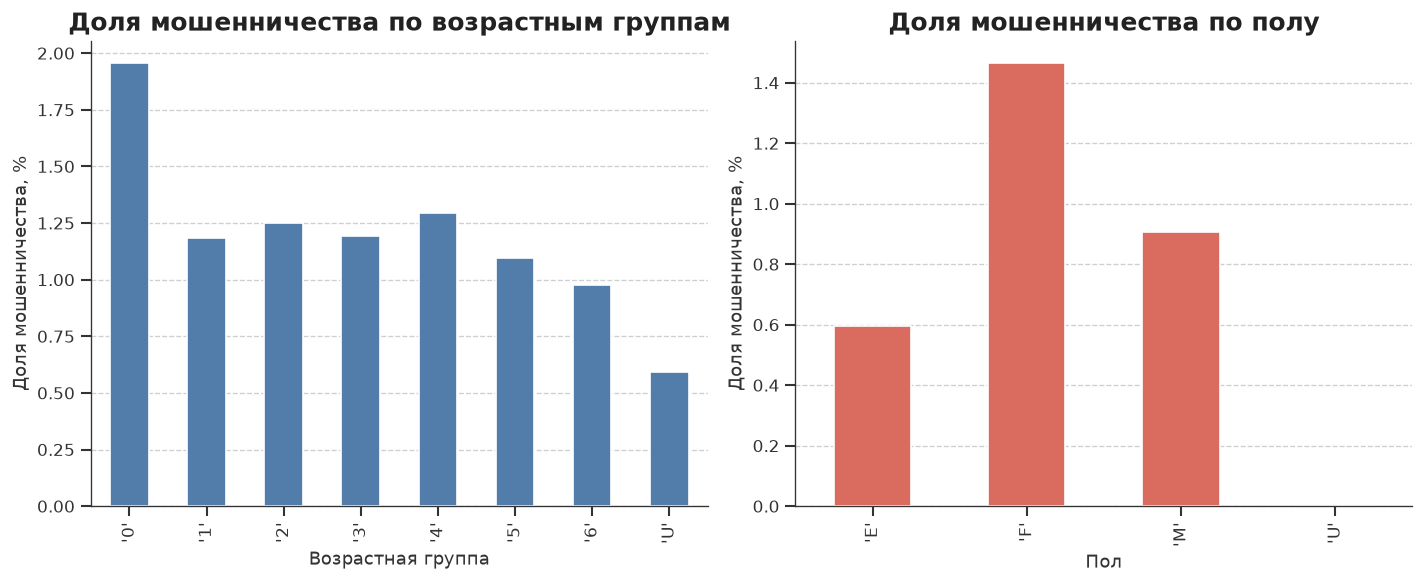

In [72]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

age_stats['fraud_rate'].plot(kind='bar', ax=axes[0], color=COLORS[0])
axes[0].set_title('Доля мошенничества по возрастным группам')
axes[0].set_xlabel('Возрастная группа')
axes[0].set_ylabel('Доля мошенничества, %')

gender_stats['fraud_rate'].plot(kind='bar', ax=axes[1], color=COLORS[1])
axes[1].set_title('Доля мошенничества по полу')
axes[1].set_xlabel('Пол')
axes[1].set_ylabel('Доля мошенничества, %')

for ax in axes:
    ax.set_axisbelow(True)
    ax.yaxis.grid(True, color='#A0A0A0', linestyle='--', linewidth=0.8, alpha=0.5)
    ax.spines[['top', 'right']].set_visible(False)

plt.tight_layout()
plt.show()

#### Выводы по демографическим признакам

Доля мошеннических операций различается между возрастными категориями и полом. Наиболее заметная разница наблюдается между категориями `F` (1.47%) и `M` (0.91%).

Однако эти признаки сами по себе не позволяют надёжно определить мошенническую операцию. Кроме того, `age` представлен условными категориями, а редкие значения `gender` имеют небольшое количество наблюдений.

Поэтому будем рассматривать эти признаки как дополнительные, а не основные факторы при оценке риска.

### 1.7. Подготовка данных

In [73]:
df.nunique().sort_values(ascending=False)

log_amount     23767
amount         23767
customer        4112
step             180
merchant          50
category          15
age                8
gender             4
fraud              2
zipMerchant        1
zipcodeOri         1
dtype: int64

In [74]:
df = df.drop(columns=['zipcodeOri', 'zipMerchant'])

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 594643 entries, 0 to 594642
Data columns (total 9 columns):
 #   Column      Non-Null Count   Dtype  
---  ------      --------------   -----  
 0   step        594643 non-null  int64  
 1   customer    594643 non-null  str    
 2   age         594643 non-null  str    
 3   gender      594643 non-null  str    
 4   merchant    594643 non-null  str    
 5   category    594643 non-null  str    
 6   amount      594643 non-null  float64
 7   fraud       594643 non-null  int64  
 8   log_amount  594643 non-null  float64
dtypes: float64(2), int64(2), str(5)
memory usage: 40.8 MB


Из датасета исключены `zipcodeOri` и `zipMerchant`, поскольку они содержали одинаковые значения во всех строках и не давали полезной информации.

В результате осталось 9 признаков и 594 643 транзакции. Пропусков нет. Идентификаторы клиентов и торговых точек сохранены для дальнейшего анализа, а также оставлен дополнительный признак `log_amount`.